# 3-qubit protocol, one round, circuit-level noise (physical level)

The physical [[3,1,1]] protocol: three copies of $R_y(\theta)|0\rangle$ with $\tan^2\theta = (\sqrt5-1)/2$ (Bloch vector ≈ (0.618, 0, 0.786)), CZ(0,1) and H(2), then CZ(1,2), then H on qubits 0 and 1. Measure qubits 0 and 1 and keep qubit 2 when both read 0. (Here H(2) uses the label `hadamard_custom` and the final H on qubits 0 and 1 use the standard `h`, so the "H noise" below acts only on H(2).)

**What this notebook computes** (x-axis: H2-2 one-qubit rate ×1…×5)
- *All errors*: depolarizing noise on `ry`, `hadamard_custom` (H on qubit 2 only) and `cz`, plus readout errors on qubits 0 and 1. Uses $10^6$ statevector shots per rate.
- *Input infidelity* of a single noisy $R_y(\theta)$ preparation.
- *Success probability* (exploratory).
- *Component analysis*: input noise only (`ideal_infidelity`, the "Optimal" reference for the logical level), plus measurement, CZ or H noise one at a time. Then the error budget, averaged over the five rates.

**Error-rate convention.** Error rates are depolarizing-equivalent parameters, $p = 2(1-F)$ for one qubit, with $F$ the fidelity to $R_y(\theta)|0\rangle$.

**Output.** `data/three_qubit/physical_level/physical_level_component_analysis.npz` (keys are *infidelities*, converted to error rates in the final-plot cells). Read here and by `../logical_level/21_qubits.ipynb`.

**Figure.** The last cell (from saved data) matches the layout and values of `figures/3Q_physical_plots.png` (H 1.9e-2, CZ 3.1e-1, Meas 6.7e-1); it has no `savefig`.

In [1]:
from qiskit import __version__
print(__version__)

2.4.1


# Importing Packages

In [17]:
import os
ncpus = os.cpu_count()
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.quantum_info import Statevector, state_fidelity, Pauli, DensityMatrix, partial_trace
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
from qiskit_aer.library import SaveDensityMatrix, SaveStatevector
from qiskit import transpile 
import numpy as np
from qiskit_aer.noise import NoiseModel, depolarizing_error, ReadoutError
from qiskit.circuit.library import HGate, UnitaryGate, IGate
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, NullFormatter
from matplotlib.patches import Rectangle
import matplotlib.ticker as mticker
from matplotlib.gridspec import GridSpec

# Defining Global Variable

In [3]:
theta = np.arctan(np.sqrt((np.sqrt(5) - 1) / 2))

# Graphing Settings

In [4]:
# --- APS-style global settings ---
mpl.rcParams.update({
    'text.usetex': True,
    'font.family': 'serif',
    'font.size': 8,
    'axes.labelsize': 9,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'legend.fontsize': 8,
    'lines.linewidth': 1.2,
    'figure.dpi': 150,
})

# Creating Custom Gates

In [5]:
# Create custom gates
H_matrix = HGate().to_matrix()
hadamard_custom = UnitaryGate(H_matrix, label='hadamard_custom')

ID_matrix = IGate().to_matrix()
encoding_err = UnitaryGate(ID_matrix, label='encoding_err')

idle_matrix = IGate().to_matrix()
idle = UnitaryGate(idle_matrix, label='idle')

ry_sub = QuantumCircuit(1, name='RY_custom')
ry_sub.ry(theta, 0)
RY_custom = ry_sub.to_gate()

# 3-Qubit MSD Circuit

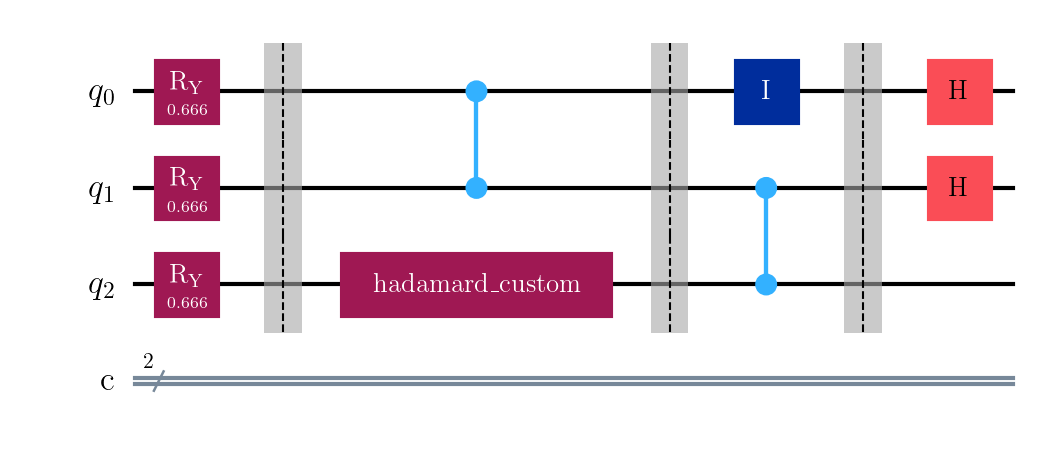

In [6]:
# Physical 3-qubit circuit (qubits 0, 1 measured; qubit 2 is the output).
# hadamard_custom lets H noise be switched on separately; id(0) is an idle slot.
circuit = QuantumCircuit(3, 2)

# State prep
for i in range(3):
    circuit.ry(theta, i)
circuit.barrier()

circuit.cz(0,1)
circuit.append(hadamard_custom, [2])
circuit.barrier()

circuit.id(0)
circuit.cz(1,2)
circuit.barrier()

circuit.h(0)
circuit.h(1)

display(circuit.draw(output='mpl'))

# Infidelity to Error Rates

In [12]:
# Output "error rate" = depolarizing-equivalent parameter: lambda = r * d/(d-1)
# for an average infidelity r on d = 2^num_qubits levels (Qiskit's
# depolarizing_error(lambda) has average infidelity lambda (d-1)/d). For one
# qubit, error rate = 2 * infidelity. Gate infidelities go through the same map.
def inf_to_error(infidelity_list, num_qubits, infidelity_uncertainty_list=None):
    if infidelity_uncertainty_list is None:
        error_rates_list = []
        dimension = 2**num_qubits
        for infidelity in infidelity_list:
            error_rates_list.append( infidelity * (dimension / (dimension - 1)) )
        
        return error_rates_list
    else:
        error_rates_list = []
        error_uncertainty_list = []

        dimension = 2**num_qubits
        scale = dimension / (dimension - 1)

        for infidelity, uncertainty in zip(infidelity_list, infidelity_uncertainty_list):
            error_rates_list.append(scale * infidelity)
            error_uncertainty_list.append(scale * uncertainty)

        return error_rates_list, error_uncertainty_list

In [13]:
# Quantinuum H2-2 infidelities scaled by 1x..5x (five points per sweep):
# one-qubit gate, two-qubit gate, idle, and readout P(1|0) (spam0) / P(0|1) (spam1).
one_qubit_gate_infidelity = [2.8e-5 * i for i in range(1,6)]
two_qubit_gate_infidelity = [8.3e-4 * i for i in range(1,6)]
idle_gate_infidelity = [1.2e-4 * i for i in range(1,6)]
spam0 = [6.7e-4 * i for i in range(1,6)] # P(1|0), measured 1 given that 0 was prepared
spam1 = [1.2e-3 * i for i in range(1,6)] # P(0|1)

In [14]:
one_qubit_gate_error_prob = inf_to_error(one_qubit_gate_infidelity, num_qubits=1)
two_qubit_gate_error_prob = inf_to_error(two_qubit_gate_infidelity, num_qubits=2)
idle_gate_error_prob = inf_to_error(idle_gate_infidelity, num_qubits=1)

# Simulations

When all physical error sources are included, we compute the infidelity of the post-selected output state vectors.

In [26]:
# Ideal dm

# Construct |000><000|.
one_q_zero_dm = np.matmul([[1], [0]], [[1, 0]])
ideal = np.kron(one_q_zero_dm, np.kron(one_q_zero_dm, one_q_zero_dm))

# Apply R_y(theta) to the first qubit.
# (First kron factor = Qiskit qubit 2, the output qubit.)
ry_theta = np.array([
    [np.cos(theta / 2), -np.sin(theta / 2)],
    [np.sin(theta / 2),  np.cos(theta / 2)]
])
ry_i_i = np.kron(ry_theta, np.kron(np.eye(2), np.eye(2)))

ideal = ry_i_i @ ideal @ ry_i_i.conj().T

# Normalize and convert to Qiskit's DensityMatrix type.
ideal /= np.trace(ideal)
ideal = DensityMatrix(ideal)

In [27]:
# Statevector sampling: each accepted shot ('0x0') is one pure-state trajectory,
# so F is averaged over accepted shots. Uncertainty = 1.96*sqrt(F(1-F)/N)
# (95% normal approximation, N = accepted shots).
# Store average fidelities and uncertainties.
all_fidelity = []
all_infidelity_unc = []

shots = 1_000_000

for i in range(len(one_qubit_gate_error_prob)):
    noise_model = NoiseModel()

    # Add depolarizing noise to each operation type.
    noise_model.add_all_qubit_quantum_error(
        depolarizing_error(one_qubit_gate_error_prob[i], 1),
        ['ry']
    )
    noise_model.add_all_qubit_quantum_error(
        depolarizing_error(one_qubit_gate_error_prob[i], 1),
        ['hadamard_custom']
    )
    noise_model.add_all_qubit_quantum_error(
        depolarizing_error(two_qubit_gate_error_prob[i], 2),
        ['cz']
    )

    # Add readout errors on the measured qubits.
    readout_err = ReadoutError([
        [1 - spam0[i], spam0[i]],
        [spam1[i], 1 - spam1[i]]
    ])
    noise_model.add_readout_error(readout_err, [0])
    noise_model.add_readout_error(readout_err, [1])

    # Measure for post-selection and save the conditional statevectors.
    meas_circuit_noise = circuit.copy()
    meas_circuit_noise.measure([0, 1], [0, 1])
    meas_circuit_noise.append(
        SaveStatevector(
            num_qubits=3,
            label='state_post',
            conditional=True,
            pershot=True
        ),
        meas_circuit_noise.qubits
    )

    # Run the noisy simulation.
    backend = AerSimulator(noise_model=noise_model, method='statevector', max_parallel_threads=ncpus)
    job = backend.run(meas_circuit_noise, shots=shots)
    result = job.result()

    # Keep only post-selected shots with measurement outcome 00.
    res_statevectors = result.data()['state_post']
    accepted_statevectors = res_statevectors['0x0']
    num_meas = len(accepted_statevectors)

    # Average fidelity over accepted shots.
    sumfid = 0
    for shot in accepted_statevectors:
        sumfid += state_fidelity(shot, ideal)

    sumfid /= num_meas

    all_fidelity.append(sumfid)

    # 95% normal-approximation uncertainty.
    all_infidelity_unc.append(
        1.96 * np.sqrt(sumfid * (1 - sumfid) / num_meas)
    )

# Convert fidelities to infidelities.
all_infidelity = [1 - f for f in all_fidelity]

Input simulations

In [66]:
# Construct |0><0|.
one_q_zero_dm = np.matmul([[1], [0]], [[1, 0]])

# Apply R_y(theta) to prepare the ideal input state.
ideal_input = ry_theta @ one_q_zero_dm @ ry_theta.conj().T

# Normalize and convert to Qiskit's DensityMatrix type.
ideal_input /= np.trace(ideal_input)
ideal_input = DensityMatrix(ideal_input)

In [67]:
input_circuit = QuantumCircuit(1)
input_circuit.ry(theta,0)

In [68]:
# Store input-state fidelities.
all_input_fidelity = []

shots = 1

for i in range(len(one_qubit_gate_error_prob)):
    nm = NoiseModel()
    
    # Apply depolarizing noise after the R_y preparation gate.
    nm.add_all_qubit_quantum_error(
        depolarizing_error(one_qubit_gate_error_prob[i], 1),
        ["ry"]
    )
    
    # Save the noisy input density matrix.
    input_copy = input_circuit.copy()
    input_copy.append(
        SaveDensityMatrix(
            num_qubits=1,
            label='dm_post',
            conditional=True,
            pershot=True
        ),
        input_copy.qubits
    )
    
    # Run density-matrix simulation.
    backend = AerSimulator(noise_model=nm, method='density_matrix')
    job = backend.run(input_copy, shots=shots)
    result = job.result()

    # Compute fidelity with the ideal input state.
    res_density_matrix = result.data()['dm_post']
    all_input_fidelity.append(
        state_fidelity(ideal_input, res_density_matrix[''][0])
    )

# Convert fidelities to infidelities.
all_input_infidelity = [1 - f for f in all_input_fidelity]

Graphing both input and output

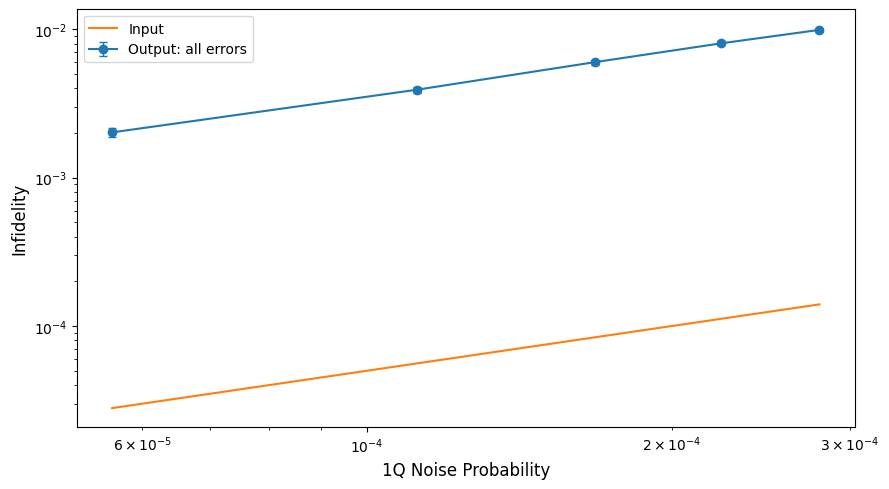

In [41]:
plt.figure(figsize=(9, 5))
plt.errorbar(
    one_qubit_gate_error_prob,
    all_infidelity,
    yerr=all_infidelity_unc,
    fmt='o-',           # circle marker and solid line
    capsize=3,          # length of the little “T” caps on each bar
    elinewidth=1,       # width of the error‐bar lines
    markeredgewidth=1,
    label='Output: all errors'
)
plt.plot(one_qubit_gate_error_prob, all_input_infidelity, label='Input')
plt.xlabel("1Q Noise Probability", fontsize=12)
plt.ylabel("Infidelity", fontsize=12)
plt.yscale('log')
plt.xscale('log')
plt.tight_layout()
plt.legend()
plt.show()

# What is the success probability

In [ ]:
shots = 100_000
success_prob_list = []

for i in range(len(one_qubit_gate_error_prob)):
    noise_model = NoiseModel()

    noise_model.add_all_qubit_quantum_error(depolarizing_error(one_qubit_gate_error_prob[i], 1), ['ry'])
    noise_model.add_all_qubit_quantum_error(depolarizing_error(one_qubit_gate_error_prob[i], 1), ['hadamard_custom'])
    noise_model.add_all_qubit_quantum_error(depolarizing_error(idle_gate_error_prob[i], 1), ['id'])
    noise_model.add_all_qubit_quantum_error(depolarizing_error(two_qubit_gate_error_prob[i], 2), ['cz']) 
    
    readout_err = ReadoutError([[1-spam0[i], spam0[i]],  # P(0|0), P(1|0)
                            [spam1[i], 1-spam1[i]]]) # P(0|1), P(1|1)
    noise_model.add_readout_error(readout_err, [0])
    noise_model.add_readout_error(readout_err, [1])

    meas_circuit_noise = circuit.copy()
    meas_circuit_noise.measure([0, 1], [0, 1]) 
    meas_circuit_noise.append(SaveStatevector(num_qubits=3, label='state_post', conditional=True, pershot=True), meas_circuit_noise.qubits)

    backend = AerSimulator(noise_model=noise_model)
    job = backend.run(meas_circuit_noise, shots=shots)
    result = job.result()
    
    res_statevectors = result.data()['state_post']
    num_meas00 = len(res_statevectors['0x0'])
    num_success = 0
    for shot in res_statevectors['0x0']:
        fid = state_fidelity(shot, ideal)
        if (round(fid, 2) == 1.00):
            num_success += 1 
            
    success_prob_list.append(num_success / num_meas00)

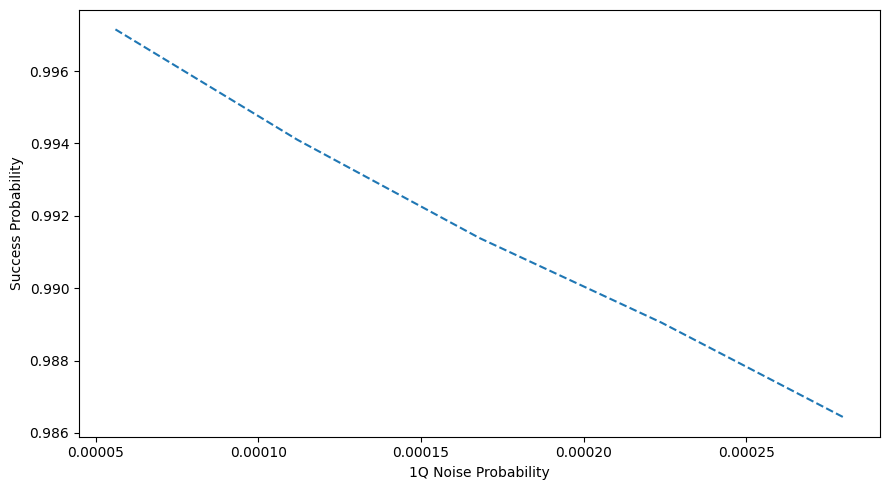

In [45]:
plt.figure(figsize=(9,5))
plt.plot(one_qubit_gate_error_prob, success_prob_list, linestyle='--')
plt.xlabel('1Q Noise Probability')
plt.ylabel('Success Probability')
plt.tight_layout()
plt.show()

# Circuit Component Analysis

In [18]:
ncpus = os.cpu_count()

In [15]:
# Post-selection: with conditional=True, Aer saves the state under the hex key
# of the classical register; '0x0' = measured qubit(s) read 0 (accepted branch).
# The density_matrix method stores the exact conditional state, so the first
# entry is used; shots only needs to be large enough to sample outcome 0.
# Entire distillation circuit is ideal
fidelity_results = []
shots = 50

for i in range(len(one_qubit_gate_error_prob)):
    noise_model = NoiseModel()
    
    noise_model.add_all_qubit_quantum_error(depolarizing_error(one_qubit_gate_error_prob[i], 1), ["ry"])
    
    meas_circuit_noise = circuit.copy()
    meas_circuit_noise.measure([0, 1], [0, 1]) 
    meas_circuit_noise.append(SaveDensityMatrix(num_qubits=3, label='dm_post', conditional=True, pershot=True), meas_circuit_noise.qubits)

    backend = AerSimulator(noise_model=noise_model, method='density_matrix')
    job = backend.run(meas_circuit_noise, shots=shots)
    result = job.result()
    
    res_dm = result.data()['dm_post']
    fidelity_results.append(state_fidelity(ideal, res_dm['0x0'][0]))
    
plot1_y = [1 - f for f in fidelity_results]

In [19]:
# Only measurement errors
fidelity_results = []
plot3_y_unc = []
shots = 1_000_000

for i in range(len(one_qubit_gate_error_prob)):
    noise_model = NoiseModel()
    
    noise_model.add_all_qubit_quantum_error(depolarizing_error(one_qubit_gate_error_prob[i], 1), ['ry'])
    readout_err = ReadoutError([[1-spam0[i], spam0[i]],  # P(0|0), P(1|0)
                            [spam1[i], 1-spam1[i]]]) # P(0|1), P(1|1)
    noise_model.add_readout_error(readout_err, [0])
    noise_model.add_readout_error(readout_err, [1])
    
    meas_circuit_noise = circuit.copy()
    meas_circuit_noise.measure([0, 1], [0, 1]) 
    
    meas_circuit_noise.append(SaveStatevector(num_qubits=3, label='state_post', conditional=True, pershot=True), meas_circuit_noise.qubits)

    backend = AerSimulator(noise_model=noise_model, method='statevector', max_parallel_threads=ncpus)
    job = backend.run(meas_circuit_noise, shots=shots)
    result = job.result()
    
    res_statevectors = result.data()['state_post']
    num_meas = len(res_statevectors['0x0'])
    sumfid = 0
    for shot in res_statevectors['0x0']:
        sumfid += state_fidelity(shot, ideal)
    sumfid /= num_meas
    
    fidelity_results.append(sumfid)
    plot3_y_unc.append( 1.96 * np.sqrt( (sumfid)*(1 - sumfid) / num_meas) )
    
plot3_y = [1 - f for f in fidelity_results]

In [ ]:
# Only cz errors
fidelity_results = []
shots = 50

for i in range(len(one_qubit_gate_error_prob)):
    noise_model = NoiseModel()
    
    noise_model.add_all_qubit_quantum_error(depolarizing_error(one_qubit_gate_error_prob[i], 1), ['ry'])
    noise_model.add_all_qubit_quantum_error(depolarizing_error(two_qubit_gate_error_prob[i], 2), ['cz']) 
    
    meas_circuit_noise = circuit.copy()
    meas_circuit_noise.measure([0, 1], [0, 1]) 
    meas_circuit_noise.append(SaveDensityMatrix(num_qubits=3, label='dm_post', conditional=True, pershot=True), meas_circuit_noise.qubits)

    backend = AerSimulator(noise_model=noise_model, method='density_matrix')
    job = backend.run(meas_circuit_noise, shots=shots)
    result = job.result()
    
    res_dm = result.data()['dm_post']
    fidelity_results.append(state_fidelity(ideal, res_dm['0x0'][0]))
    
plot4_y = [1 - f for f in fidelity_results]

In [ ]:
# Only hadamard errors
fidelity_results = []
shots = 50

for i in range(len(one_qubit_gate_error_prob)):
    noise_model = NoiseModel()
    
    noise_model.add_all_qubit_quantum_error(depolarizing_error(one_qubit_gate_error_prob[i], 1), ['ry'])
    noise_model.add_all_qubit_quantum_error(depolarizing_error(one_qubit_gate_error_prob[i], 1), ['hadamard_custom'])
    
    meas_circuit_noise = circuit.copy()
    meas_circuit_noise.measure([0, 1], [0, 1]) 
    meas_circuit_noise.append(SaveDensityMatrix(num_qubits=3, label='dm_post', conditional=True, pershot=True), meas_circuit_noise.qubits)

    backend = AerSimulator(noise_model=noise_model, method='density_matrix')
    job = backend.run(meas_circuit_noise, shots=shots)
    result = job.result()
    
    res_dm = result.data()['dm_post']
    fidelity_results.append(state_fidelity(ideal, res_dm['0x0'][0]))
    
plot5_y = [1 - f for f in fidelity_results]

Final Plot

In [32]:
plot1_output_error_rate = inf_to_error(plot1_y,1)
plot3_output_error_rate = inf_to_error(plot3_y,1)
plot4_output_error_rate = inf_to_error(plot4_y,1)
plot5_output_error_rate = inf_to_error(plot5_y,1)
all_output_error_rate = inf_to_error(all_infidelity, 1)

In [ ]:
# Error budget. Every component run (one noisy gate type or readout) also
# carries the input-state noise, and that noise alone is the noise-free
# "Ideal" run. The error a component adds is therefore its output error rate
# minus the Ideal baseline; to first order these excesses add up. At each
# rate, each component's excess is taken as a fraction of the summed excesses,
# and the fractions are averaged over the rates. An excess below zero (a
# component statistically indistinguishable from the baseline) is set to zero.
baseline = np.asarray(plot1_output_error_rate, dtype=float)
excess = np.clip(
    np.array([plot5_output_error_rate, plot4_output_error_rate, plot3_output_error_rate], dtype=float) - baseline,
    0.0, None
)
total_excess = excess.sum(axis=0)
valid = total_excess > 0
fractions = excess[:, valid] / total_excess[valid]

for i, e in enumerate(one_qubit_gate_error_prob):
    print(f"For 1Q error probability = {e}")
    for label, row in zip(['Hadamard', 'CZ', 'Measurement'], excess):
        frac = row[i] / total_excess[i] if total_excess[i] > 0 else float('nan')
        print(f"{label} Fractions = {frac}")
    print("")

hadamard_contributions, cz_contributions, measurement_contributions = fractions.mean(axis=1)

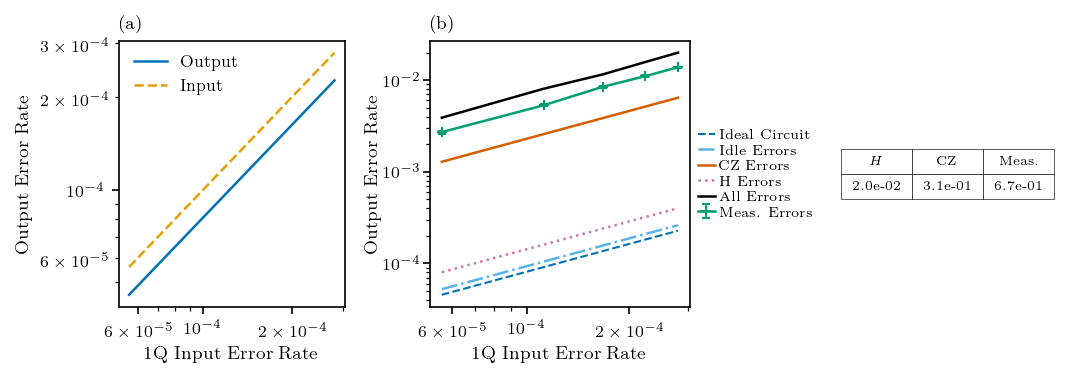

In [54]:
fig = plt.figure(figsize=(6.75, 2.65))

# Layout:
# plot 1 | spacer | plot 2 | legend | spacer | table
gs = GridSpec(
    1, 6,
    figure=fig,
    width_ratios=[1.0, 0.35, 1.15, 0.55, 0.14, 0.82],
    wspace=0.02
)

ax1 = fig.add_subplot(gs[0])
ax_spacer_12 = fig.add_subplot(gs[1])
ax2 = fig.add_subplot(gs[2])
ax_leg = fig.add_subplot(gs[3])
ax_spacer_lt = fig.add_subplot(gs[4])
ax_table = fig.add_subplot(gs[5])

ax_spacer_12.axis('off')
ax_spacer_lt.axis('off')
ax_leg.axis('off')
ax_table.axis('off')

# ── Plot 1 ───────────────────────────────────────────────
ax1.plot(
    one_qubit_gate_error_prob,
    plot1_output_error_rate,
    color='#0072B2',
    linestyle='-',
    label='Output'
)

ax1.plot(
    one_qubit_gate_error_prob,
    one_qubit_gate_error_prob,
    color='#E69F00',
    linestyle='--',
    label='Input'
)

ax1.set_xscale('log')
ax1.set_yscale('log')

ax1.set_xticks([6e-5, 1e-4, 2e-4])
ax1.set_xticklabels([r'$6\times10^{-5}$', r'$10^{-4}$', r'$2\times10^{-4}$'])
ax1.xaxis.set_minor_formatter(mticker.NullFormatter())

ax1.legend(frameon=False, loc='upper left')
ax1.set_ylabel('Output Error Rate')
ax1.set_xlabel('1Q Input Error Rate')
ax1.set_title('(a)', loc='left', fontsize=9)

# ── Plot 2 ───────────────────────────────────────────────
ax2.plot(
    one_qubit_gate_error_prob,
    plot1_output_error_rate,
    color='#0072B2',
    linestyle='--',
    linewidth=1.0,
    label='Ideal Circuit'
)

ax2.plot(
    one_qubit_gate_error_prob,
    plot4_output_error_rate,
    color='#D55E00',
    linestyle='-',
    label='CZ Errors'
)

ax2.plot(
    one_qubit_gate_error_prob,
    plot5_output_error_rate,
    color='#CC79A7',
    linestyle=':',
    label='H Errors'
)

ax2.plot(
    one_qubit_gate_error_prob,
    all_output_error_rate,
    color='#000000',
    linestyle='-',
    label='All Errors'
)

ax2.errorbar(
    one_qubit_gate_error_prob,
    plot3_output_error_rate,
    yerr=plot3_y_unc,
    fmt='+-',
    color='#009E73',
    capsize=2,
    markersize=5,
    elinewidth=0.8,
    label='Meas. Errors'
)

ax2.set_xscale('log')
ax2.set_yscale('log')

ax2.set_xticks([6e-5, 1e-4, 2e-4])
ax2.set_xticklabels([r'$6\times10^{-5}$', r'$10^{-4}$', r'$2\times10^{-4}$'])
ax2.xaxis.set_minor_formatter(mticker.NullFormatter())

ax2.set_ylabel('Output Error Rate')
ax2.set_xlabel('1Q Input Error Rate')
ax2.set_title('(b)', loc='left', fontsize=9)

# Make plot 2 y-axis label/ticks compact
ax2.yaxis.labelpad = 1
ax2.tick_params(axis='y', which='both', pad=1)

# ── Legend right of Plot 2 ───────────────────────────────
handles, labels = ax2.get_legend_handles_labels()

ax_leg.legend(
    handles,
    labels,
    loc='center left',
    frameon=False,
    fontsize=6.5,
    handlelength=1.2,
    handletextpad=0.35,
    labelspacing=0.25,
    borderaxespad=0.0
)

# ── Table right of legend ────────────────────────────────
table_data = [
    [r'$H$', r'CZ', r'Meas.'],
    [
        f'{hadamard_contributions:.1e}',
        f'{cz_contributions:.1e}',
        f'{measurement_contributions:.1e}'
    ]
]

table = ax_table.table(
    cellText=table_data,
    cellLoc='center',
    loc='center'
)

table.auto_set_font_size(False)
table.set_fontsize(6.2)
table.scale(1.15, 1.15)

for cell in table.get_celld().values():
    cell.set_linewidth(0.3)

fig.subplots_adjust(
    left=0.08,
    right=0.99,
    bottom=0.23,
    top=0.90
)

plt.show()

# Saving and Loading Data

In [28]:
# Saved values are infidelities (not yet converted to error rates).
# Saving Data
np.savez("../../../data/three_qubit/physical_level/physical_level_component_analysis.npz",
    ideal_infidelity=plot1_y,
    meas_infidelity=plot3_y,
    meas_infidelity_unc=plot3_y_unc,
    cz_infidelity=plot4_y,
    h_infidelity=plot5_y,
    one_qubit_gate_error_prob=one_qubit_gate_error_prob,
    all_infidelity=all_infidelity,
    all_infidelity_unc=all_infidelity_unc
)

In [29]:
# Loading Data
data = np.load("../../../data/three_qubit/physical_level/physical_level_component_analysis.npz")

ideal_infidelity = data["ideal_infidelity"]
meas_infidelity = data["meas_infidelity"]
meas_infidelity_unc = data["meas_infidelity_unc"]
cz_infidelity = data["cz_infidelity"]
h_infidelity = data["h_infidelity"]
one_qubit_gate_error_prob = data["one_qubit_gate_error_prob"]
all_infidelity = data["all_infidelity"]
all_infidelity_unc = data["all_infidelity_unc"]

# Final Plot

In [30]:
ideal_output_error_rate = inf_to_error(ideal_infidelity,1)
meas_output_error_rate, meas_output_error_rate_unc = inf_to_error(meas_infidelity, 1, meas_infidelity_unc)
cz_output_error_rate = inf_to_error(cz_infidelity,1)
h_output_error_rate = inf_to_error(h_infidelity,1)
all_output_error_rate, all_output_error_rate_unc = inf_to_error(all_infidelity, 1, all_infidelity_unc)

In [ ]:
# Error budget. Every component run (one noisy gate type or readout) also
# carries the input-state noise, and that noise alone is the noise-free
# "Ideal" run. The error a component adds is therefore its output error rate
# minus the Ideal baseline; to first order these excesses add up. At each
# rate, each component's excess is taken as a fraction of the summed excesses,
# and the fractions are averaged over the rates. An excess below zero (a
# component statistically indistinguishable from the baseline) is set to zero.
baseline = np.asarray(ideal_output_error_rate, dtype=float)
excess = np.clip(
    np.array([h_output_error_rate, cz_output_error_rate, meas_output_error_rate], dtype=float) - baseline,
    0.0, None
)
total_excess = excess.sum(axis=0)
valid = total_excess > 0
fractions = excess[:, valid] / total_excess[valid]

hadamard_contributions, cz_contributions, measurement_contributions = fractions.mean(axis=1)

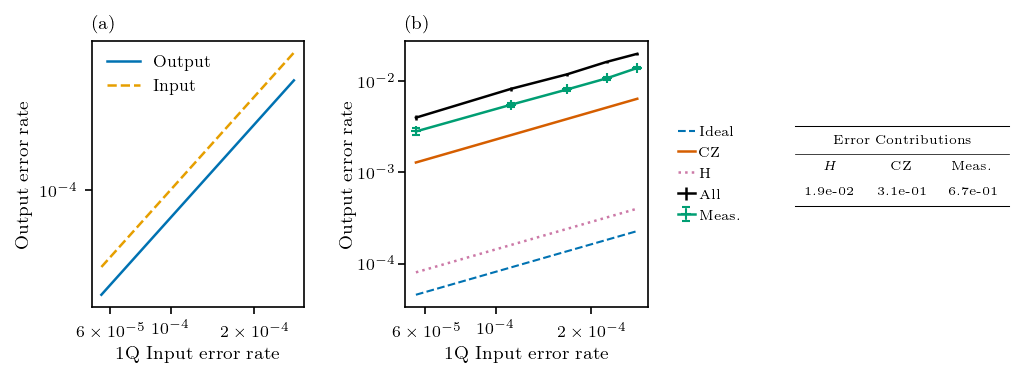

In [35]:
fig = plt.figure(figsize=(6.75, 2.65))

# Layout:
# plot 1 | spacer | plot 2 | legend | small spacer | table
gs = GridSpec(
    1, 6,
    figure=fig,
    width_ratios=[1.0, 0.45, 1.15, 0.55, 0.08, 1.05],
    wspace=0.02
)

ax1 = fig.add_subplot(gs[0])
ax_spacer_12 = fig.add_subplot(gs[1])
ax2 = fig.add_subplot(gs[2])
ax_leg = fig.add_subplot(gs[3])
ax_spacer_lt = fig.add_subplot(gs[4])
ax_table = fig.add_subplot(gs[5])

ax_spacer_12.axis('off')
ax_spacer_lt.axis('off')
ax_leg.axis('off')
ax_table.axis('off')

# ── Plot 1 ───────────────────────────────────────────────
ax1.plot(
    one_qubit_gate_error_prob,
    ideal_output_error_rate,
    color='#0072B2',
    linestyle='-',
    label='Output'
)

ax1.plot(
    one_qubit_gate_error_prob,
    one_qubit_gate_error_prob,
    color='#E69F00',
    linestyle='--',
    label='Input'
)

ax1.set_xscale('log')
ax1.set_yscale('log')

ax1.set_xticks([6e-5, 1e-4, 2e-4])
ax1.set_xticklabels([r'$6\times10^{-5}$', r'$10^{-4}$', r'$2\times10^{-4}$'])
ax1.xaxis.set_minor_locator(mticker.NullLocator())
ax1.xaxis.set_minor_formatter(mticker.NullFormatter())
ax1.yaxis.set_minor_locator(mticker.NullLocator())
ax1.yaxis.set_minor_formatter(mticker.NullFormatter())

ax1.legend(frameon=False, loc='upper left')
ax1.set_ylabel('Output error rate')
ax1.set_xlabel('1Q Input error rate')
ax1.set_title('(a)', loc='left', fontsize=9)

# ── Plot 2 ───────────────────────────────────────────────
ax2.plot(
    one_qubit_gate_error_prob,
    ideal_output_error_rate,
    color='#0072B2',
    linestyle='--',
    linewidth=1.0,
    label='Ideal'
)

ax2.plot(
    one_qubit_gate_error_prob,
    cz_output_error_rate,
    color='#D55E00',
    linestyle='-',
    label='CZ'
)

ax2.plot(
    one_qubit_gate_error_prob,
    h_output_error_rate,
    color='#CC79A7',
    linestyle=':',
    label='H'
)

ax2.errorbar(
    one_qubit_gate_error_prob,
    all_output_error_rate,
    yerr=all_output_error_rate_unc,
    color='#000000',
    linestyle='-',
    label='All'
)

ax2.errorbar(
    one_qubit_gate_error_prob,
    meas_output_error_rate,
    yerr=meas_output_error_rate_unc,
    fmt='+-',
    color='#009E73',
    capsize=2,
    markersize=5,
    elinewidth=0.8,
    label='Meas.'
)

ax2.set_xscale('log')
ax2.set_yscale('log')

ax2.set_xticks([6e-5, 1e-4, 2e-4])
ax2.set_xticklabels([r'$6\times10^{-5}$', r'$10^{-4}$', r'$2\times10^{-4}$'])
ax2.xaxis.set_minor_locator(mticker.NullLocator())
ax2.xaxis.set_minor_formatter(mticker.NullFormatter())
ax2.yaxis.set_minor_locator(mticker.NullLocator())
ax2.yaxis.set_minor_formatter(mticker.NullFormatter())

ax2.set_ylabel('Output error rate')
ax2.set_xlabel('1Q Input error rate')
ax2.set_title('(b)', loc='left', fontsize=9)

# Make plot 2 y-axis label/ticks compact
ax2.yaxis.labelpad = 1
ax2.tick_params(axis='y', which='both', pad=1)

# ── Legend right of Plot 2 ───────────────────────────────
handles, labels = ax2.get_legend_handles_labels()

ax_leg.legend(
    handles,
    labels,
    loc='center',
    frameon=False,
    fontsize=6.5,
    handlelength=1.2,
    handletextpad=0.35,
    labelspacing=0.65,
    borderaxespad=0.0
)

# ── Table right of legend ────────────────────────────────
ax_table.axis('off')
ax_table.set_xlim(0, 1)
ax_table.set_ylim(0, 1)

headers = [r'$H$', r'CZ', r'Meas.']
values = [
    f'{hadamard_contributions:.1e}',
    f'{cz_contributions:.1e}',
    f'{measurement_contributions:.1e}'
]

# Table position inside ax_table
x0 = 0.02
y0 = 0.38
width = 0.96
height = 0.30

col_w = width / 3

# Row y-positions
y_title = y0 + 0.82 * height
y_header = y0 + 0.50 * height
y_values = y0 + 0.18 * height

# Horizontal rule positions
y_top = y0 + height
y_mid = y0 + 0.65 * height
y_bottom = y0

# Font sizes
fs_title = 6.2
fs_body = 5.8

# Title
ax_table.text(
    x0 + width / 2,
    y_title,
    'Error Contributions',
    ha='center',
    va='center',
    fontsize=fs_title,
    fontweight='semibold',
    transform=ax_table.transAxes
)

# Horizontal rules only
ax_table.plot(
    [x0, x0 + width],
    [y_top, y_top],
    color='black',
    linewidth=0.5,
    transform=ax_table.transAxes,
    clip_on=False
)

ax_table.plot(
    [x0, x0 + width],
    [y_mid, y_mid],
    color='black',
    linewidth=0.35,
    transform=ax_table.transAxes,
    clip_on=False
)

ax_table.plot(
    [x0, x0 + width],
    [y_bottom, y_bottom],
    color='black',
    linewidth=0.5,
    transform=ax_table.transAxes,
    clip_on=False
)

# Headers and values
for j, header in enumerate(headers):
    x = x0 + (j + 0.5) * col_w

    ax_table.text(
        x,
        y_header,
        header,
        ha='center',
        va='center',
        fontsize=fs_body,
        transform=ax_table.transAxes
    )

    ax_table.text(
        x,
        y_values,
        values[j],
        ha='center',
        va='center',
        fontsize=fs_body,
        transform=ax_table.transAxes
    )

fig.subplots_adjust(
    left=0.08,
    right=0.99,
    bottom=0.23,
    top=0.90
)

plt.show()